# Comparaison de SimpleRNN, LSTM et GRU

**Objectif :** prédire la prochaine valeur d'un signal périodique bruité à partir des 40 valeurs précédentes.

Nous construirons cette expérience progressivement : données, séquences, modèles, entraînement et comparaison.

## 1. Vérification de l'environnement
Exécuter la cellule suivante avec la noyau **Python (RNN-LSTM-GRU | WSL GPU)**.

In [6]:
import sys
import tensorflow as tf
import keras

# Vérifier l'interpréteur et les versions réellement utilisés.
print("Interpréteur Python :", sys.executable)
print("Version Python :", sys.version.split()[0])
print("Version TensorFlow :", tf.__version__)
print("Version Keras :", keras.__version__)

# Détecter les GPU visibles, sans lancer d'entraînement.
gpus = tf.config.list_physical_devices("GPU")
print("GPU détectés :", gpus)
print("Nombre de GPU :", len(gpus))

Interpréteur Python : /mnt/c/Users/marou/Desktop/ENSET/IA_Avance/RNN_LSTM_GRU/.venv/bin/python
Version Python : 3.12.3
Version TensorFlow : 2.21.0
Version Keras : 3.15.1
GPU détectés : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Nombre de GPU : 1


## 2. Création et visualisation des données
Une série temporelle est une suite de mesures ordonnées dans le temps. Nous créons 2 000 valeurs : une onde sinusoïdale de période 50, accompagnée d'un bruit léger.

La graine 42 permet de reproduire les mêmes données. Une période de 50 signifie que le motif se répète toutes les 50 étapes. Le bruit ajoute de petites variations aléatoires. La forme `(2000,)` décrit un tableau à un axe contenant 2 000 mesures.

**Résultat attendu :** six cycles sur les 300 premières mesures et une image sauvegardée pour la présentation.

Nombre de mesures : 2000
Dimensions du signal : (2000,)
Cinq premières valeurs : [0.03  0.021 0.324 0.462 0.287]


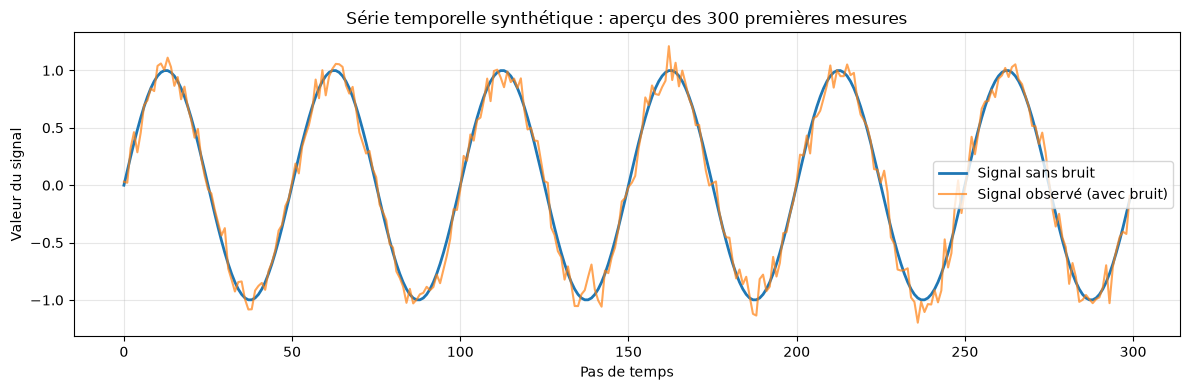

Figure enregistrée : figures/01_signal_synthetique.png


In [7]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Créer les dossiers destinés aux figures et aux résultats.
DOSSIER_FIGURES = Path('figures')
DOSSIER_RESULTATS = Path('resultats')
DOSSIER_FIGURES.mkdir(exist_ok=True)
DOSSIER_RESULTATS.mkdir(exist_ok=True)

# Fixer la graine pour reproduire les mêmes données.
GRAINE = 42
generateur = np.random.default_rng(GRAINE)
N_POINTS = 2000
temps = np.arange(N_POINTS)

# Construire une onde de période 50 et ajouter un bruit léger.
PERIODE = 50
signal_propre = np.sin(2 * np.pi * temps / PERIODE)
bruit = generateur.normal(loc=0.0, scale=0.1, size=N_POINTS)
signal = (signal_propre + bruit).astype(np.float32)

print('Nombre de mesures :', len(signal))
print('Dimensions du signal :', signal.shape)
print('Cinq premières valeurs :', np.round(signal[:5], 3))

# Visualiser les 300 premières mesures.
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(temps[:300], signal_propre[:300], label='Signal sans bruit', linewidth=2)
ax.plot(temps[:300], signal[:300], label='Signal observé (avec bruit)', alpha=0.7)
ax.set_title('Série temporelle synthétique : aperçu des 300 premières mesures')
ax.set_xlabel('Pas de temps')
ax.set_ylabel('Valeur du signal')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

# Sauvegarder la figure pour la présentation finale.
chemin_figure = DOSSIER_FIGURES / '01_signal_synthetique.png'
fig.savefig(chemin_figure, dpi=200, bbox_inches='tight')
plt.show()
print('Figure enregistrée :', chemin_figure)

## 3. Comprendre une fenêtre et sa cible
Un exemple associe 40 mesures passées (entrée) à la mesure suivante (cible). Python commence à compter à zéro : les indices 0 à 39 constituent l'entrée et l'indice 40 désigne la 41e mesure.

`signal[:40]` sélectionne les indices 0 à 39 : la borne 40 est exclue. Le réseau recevra ces mesures dans leur ordre temporel. La cible sert à mesurer son erreur pendant l'entraînement, sans être incluse dans l'entrée.

Nous illustrons un seul exemple. Le point rouge est la cible connue dans nos données, pas une prédiction du modèle.

Dimensions de cette entrée : (40,)
Indices utilisés en entrée : 0 à 39
Indice de la cible : 40
Valeur de la cible : -0.877


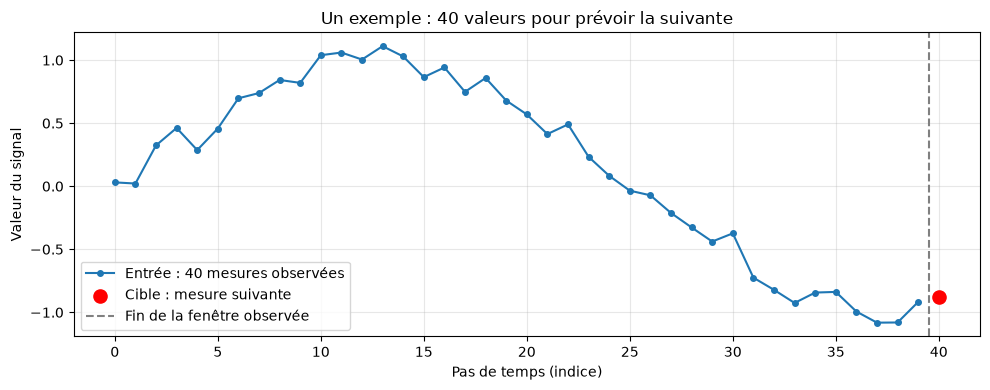

Figure enregistrée : figures/02_fenetre_et_cible.png


In [8]:
# Choisir les 40 premières mesures comme entrée.
LONGUEUR_SEQUENCE = 40
entree_exemple = signal[:LONGUEUR_SEQUENCE]
cible_exemple = signal[LONGUEUR_SEQUENCE]

print('Dimensions de cette entrée :', entree_exemple.shape)
print('Indices utilisés en entrée : 0 à 39')
print('Indice de la cible :', LONGUEUR_SEQUENCE)
print('Valeur de la cible :', round(float(cible_exemple), 3))

# Distinguer le passé observé et la prochaine mesure à prédire.
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(temps[:LONGUEUR_SEQUENCE], entree_exemple, 'o-',
        markersize=4, label='Entrée : 40 mesures observées')
ax.scatter(temps[LONGUEUR_SEQUENCE], cible_exemple,
           color='red', s=90, zorder=3, label='Cible : mesure suivante')
ax.axvline(LONGUEUR_SEQUENCE - 0.5, color='gray', linestyle='--',
           label='Fin de la fenêtre observée')
ax.set_title('Un exemple : 40 valeurs pour prévoir la suivante')
ax.set_xlabel('Pas de temps (indice)')
ax.set_ylabel('Valeur du signal')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
chemin_figure = DOSSIER_FIGURES / '02_fenetre_et_cible.png'
fig.savefig(chemin_figure, dpi=200, bbox_inches='tight')
plt.show()
print('Figure enregistrée :', chemin_figure)

## 4. Construire les séquences et comprendre leurs dimensions

La fenêtre avance d'une mesure à chaque exemple :
- Exemple 0 : indices 0 à 39 → cible d'indice 40.
- Exemple 1 : indices 1 à 40 → cible d'indice 41.
- Dernier exemple : indices 1959 à 1998 → cible d'indice 1999.

Avec 2 000 mesures et une fenêtre de 40, nous obtenons 1 960 exemples. Les fenêtres voisines se chevauchent : c'est normal. Nous les séparerons ensuite chronologiquement selon l'indice de leur cible, sans mélange aléatoire.

Les réseaux récurrents attendent une entrée de forme **(nombre d'exemples, pas de temps, variables par pas)** : ici `(1960, 40, 1)`. Une seule variable est observée à chaque instant. Chaque cible contient une seule valeur, d'où la forme `(1960, 1)`.

Aucun modèle n'est entraîné dans cette cellule.

In [10]:
# Construire toutes les fenêtres dans leur ordre chronologique.
fenetres = []
cibles = []
indices_cibles = np.arange(LONGUEUR_SEQUENCE, len(signal))

for indice_cible in indices_cibles:
    # La borne de droite est exclue : la cible reste hors de l'entrée.
    debut = indice_cible - LONGUEUR_SEQUENCE
    fenetres.append(signal[debut:indice_cible])
    cibles.append(signal[indice_cible])

# Avant adaptation : (nombre d'exemples, longueur de la fenêtre).
X_2d = np.array(fenetres, dtype=np.float32)

# Ajouter un axe : une variable observée à chaque pas de temps.
X = X_2d[..., np.newaxis]
y = np.array(cibles, dtype=np.float32).reshape(-1, 1)

print('Nombre d’exemples :', len(X))
print('Avant ajout de l’axe des variables :', X_2d.shape)
print('Dimensions de X (exemples, temps, variables) :', X.shape)
print('Dimensions de y (exemples, valeur cible) :', y.shape)

# Montrer le déplacement de la fenêtre sur les trois premiers exemples.
for numero in range(3):
    fin = int(indices_cibles[numero])
    print(f'Exemple {numero} : entrée indices {fin - LONGUEUR_SEQUENCE} à {fin - 1}'
          f' → cible indice {fin}, valeur {y[numero, 0]:.3f}')

# Vérifier que le premier exemple correspond à la figure précédente.
assert np.array_equal(X[0, :, 0], entree_exemple)
assert y[0, 0] == cible_exemple
print('Vérification réussie : le premier exemple correspond à notre figure.')

Nombre d’exemples : 1960
Avant ajout de l’axe des variables : (1960, 40)
Dimensions de X (exemples, temps, variables) : (1960, 40, 1)
Dimensions de y (exemples, valeur cible) : (1960, 1)
Exemple 0 : entrée indices 0 à 39 → cible indice 40, valeur -0.877
Exemple 1 : entrée indices 1 à 40 → cible indice 41, valeur -0.851
Exemple 2 : entrée indices 2 à 41 → cible indice 42, valeur -0.911
Vérification réussie : le premier exemple correspond à notre figure.


## 5. Séparer les données dans le temps

Nous réservons les premiers 70 % des exemples à l'entraînement, les 15 % suivants à la validation et les derniers 15 % au test.

- Entraînement : ajuster les poids du modèle.
- Validation : suivre l'apprentissage et choisir les réglages.
- Test : évaluer une dernière fois les modèles retenus, sans utiliser ce jeu pour les régler.

Les exemples restent dans l'ordre chronologique. Les trois modèles utiliseront exactement les mêmes divisions. Ici, chaque prédiction vise la prochaine mesure à partir des 40 mesures réellement observées juste avant : c'est une évaluation glissante à un pas, pas une prévision de tout le futur d'un seul coup.

Les premières fenêtres de validation et de test peuvent donc contenir des observations de la période précédente. C'est autorisé : il s'agit du passé disponible à l'instant de la prédiction. Les indices des cibles des trois jeux restent distincts et ordonnés. Aucune normalisation n'est appliquée ici ; si nous en ajoutons une, elle sera ajustée uniquement sur l'entraînement.

**Résultats attendus :** 1 372 exemples d'entraînement, 294 de validation et 294 de test.

Entraînement : X (1372, 40, 1), y (1372, 1) | indices des cibles : 40 à 1411
Validation : X (294, 40, 1), y (294, 1) | indices des cibles : 1412 à 1705
Test : X (294, 40, 1), y (294, 1) | indices des cibles : 1706 à 1999


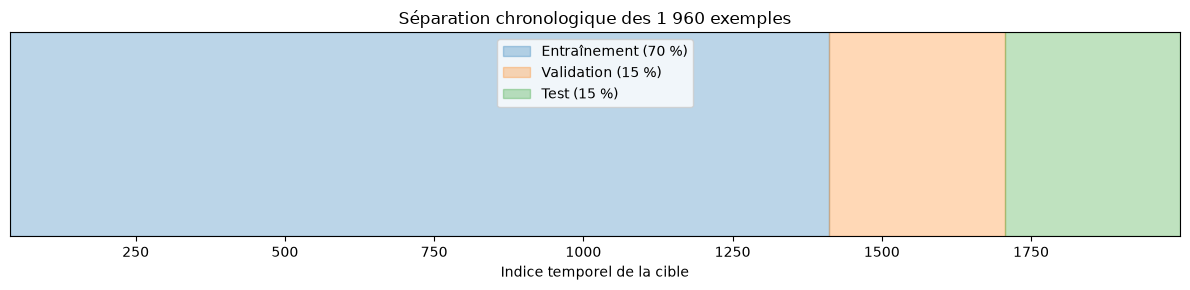

Figure enregistrée : figures/03_separation_chronologique.png


In [11]:
# Calculer les limites sans mélanger l'ordre des exemples.
n_exemples = len(X)
n_train = int(0.70 * n_exemples)
n_validation = int(0.15 * n_exemples)
fin_validation = n_train + n_validation

# Découper les entrées et leurs cibles aux mêmes positions.
X_train, y_train = X[:n_train], y[:n_train]
X_val, y_val = X[n_train:fin_validation], y[n_train:fin_validation]
X_test, y_test = X[fin_validation:], y[fin_validation:]

# Conserver les indices temporels des cibles pour les futurs graphiques.
t_train = indices_cibles[:n_train]
t_val = indices_cibles[n_train:fin_validation]
t_test = indices_cibles[fin_validation:]

for nom, entrees, cibles_jeu, indices in [
    ('Entraînement', X_train, y_train, t_train),
    ('Validation', X_val, y_val, t_val),
    ('Test', X_test, y_test, t_test),
]:
    print(f'{nom} : X {entrees.shape}, y {cibles_jeu.shape}'
          f' | indices des cibles : {indices[0]} à {indices[-1]}')

# Vérifier la chronologie et la conservation de tous les exemples.
assert t_train[-1] < t_val[0]
assert t_val[-1] < t_test[0]
assert len(X_train) + len(X_val) + len(X_test) == len(X)

# Représenter les périodes sans afficher les valeurs du test.
fig, ax = plt.subplots(figsize=(12, 3))
for indices, couleur, etiquette in [
    (t_train, 'tab:blue', 'Entraînement (70 %)'),
    (t_val, 'tab:orange', 'Validation (15 %)'),
    (t_test, 'tab:green', 'Test (15 %)'),
]:
    ax.axvspan(indices[0] - 0.5, indices[-1] + 0.5,
               color=couleur, alpha=0.3, label=etiquette)
ax.set_xlim(indices_cibles[0] - 0.5, indices_cibles[-1] + 0.5)
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_xlabel('Indice temporel de la cible')
ax.set_title('Séparation chronologique des 1 960 exemples')
ax.legend(loc='upper center')
fig.tight_layout()
chemin_figure = DOSSIER_FIGURES / '03_separation_chronologique.png'
fig.savefig(chemin_figure, dpi=200, bbox_inches='tight')
plt.show()
print('Figure enregistrée :', chemin_figure)

## 6. Établir une référence naïve sur la validation

La méthode de persistance prévoit que la prochaine valeur sera égale à la dernière observation de la fenêtre. Elle ne possède aucun paramètre entraînable et ne nécessite aucun entraînement.

Exemple : pour une fenêtre qui se termine par `[0.2, 0.4, 0.5]`, la prévision est `0.5`. Si la cible est `0.6`, l'erreur absolue vaut `0.1`.

Deux mesures serviront pour tous les modèles :
- **MAE** : moyenne des valeurs absolues des erreurs.
- **RMSE** : racine carrée de la moyenne des erreurs au carré ; elle pénalise davantage les grandes erreurs.

Ces deux mesures sont exprimées dans l'unité du signal et doivent être aussi petites que possible. Nous évaluons ici uniquement la validation. Le test reste réservé à l'évaluation finale.

La figure et le tableau CSV sont conservés pour la présentation. Ils représentent une référence de validation, pas encore la comparaison finale.

                       Modèle        Jeu    MAE   RMSE  Paramètres entraînables
Persistance (référence naïve) Validation 0.1425 0.1765                        0


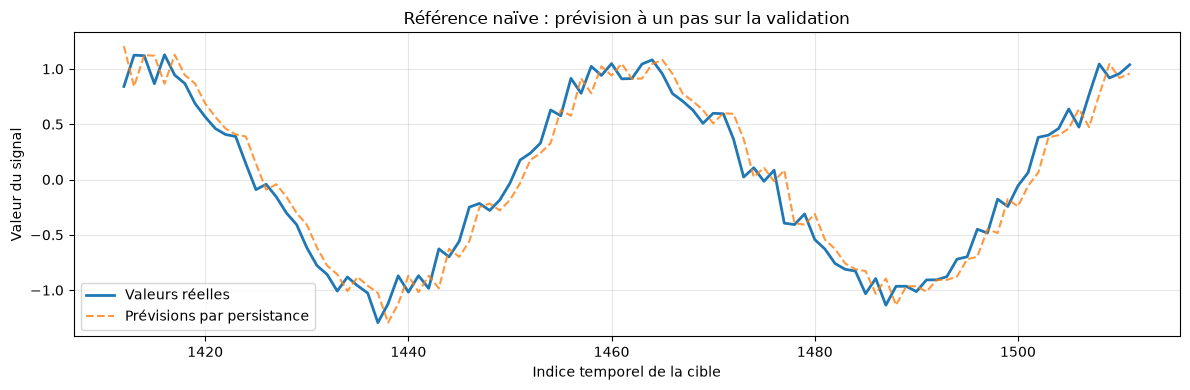

Tableau enregistré : resultats/reference_validation.csv
Figure enregistrée : figures/04_reference_naive_validation.png


In [13]:
import pandas as pd

# Définir une fonction commune aux futures évaluations.
def calculer_metriques(valeurs_reelles, predictions):
    # Utiliser des vecteurs de même forme pour éviter un calcul par diffusion.
    valeurs_reelles = np.asarray(valeurs_reelles, dtype=np.float64).reshape(-1)
    predictions = np.asarray(predictions, dtype=np.float64).reshape(-1)
    if valeurs_reelles.shape != predictions.shape:
        raise ValueError('Les valeurs réelles et les prédictions doivent avoir la même forme.')
    erreurs = predictions - valeurs_reelles
    mae = np.mean(np.abs(erreurs))
    rmse = np.sqrt(np.mean(erreurs ** 2))
    return {'MAE': float(mae), 'RMSE': float(rmse)}

# Pour chaque fenêtre, reprendre la dernière mesure observée.
# Axes de X_val : (exemple, pas de temps, variable).
predictions_naives_val = X_val[:, -1, 0]
metriques_naives_val = calculer_metriques(y_val, predictions_naives_val)

reference_validation = pd.DataFrame([{
    'Modèle': 'Persistance (référence naïve)',
    'Jeu': 'Validation',
    'MAE': metriques_naives_val['MAE'],
    'RMSE': metriques_naives_val['RMSE'],
    'Paramètres entraînables': 0,
}])
print(reference_validation.to_string(index=False, float_format=lambda valeur: f'{valeur:.4f}'))
chemin_tableau = DOSSIER_RESULTATS / 'reference_validation.csv'
reference_validation.to_csv(chemin_tableau, index=False)

# Comparer les prévisions et les cibles sur 100 instants de validation.
n_affiches = min(100, len(y_val))
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t_val[:n_affiches], y_val[:n_affiches, 0],
        label='Valeurs réelles', linewidth=2)
ax.plot(t_val[:n_affiches], predictions_naives_val[:n_affiches],
        label='Prévisions par persistance', linestyle='--', alpha=0.8)
ax.set_title('Référence naïve : prévision à un pas sur la validation')
ax.set_xlabel('Indice temporel de la cible')
ax.set_ylabel('Valeur du signal')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
chemin_figure = DOSSIER_FIGURES / '04_reference_naive_validation.png'
fig.savefig(chemin_figure, dpi=200, bbox_inches='tight')
plt.show()
print('Tableau enregistré :', chemin_tableau)
print('Figure enregistrée :', chemin_figure)

## 7. Construire les trois modèles sans entraînement

Architecture commune : entrée `(40, 1)` → couche récurrente de 32 unités → couche Dense de sortie à une valeur.

Les 40 pas sont lus successivement. Les 32 unités représentent la taille de l'état caché, pas le nombre de mesures. Avec `return_sequences=False`, la couche transmet seulement son dernier état caché à la couche de sortie. LSTM conserve aussi un état de cellule interne.

`Dense(1)` combine les 32 composantes finales pour produire une valeur numérique. Aucun entraînement n'a encore eu lieu : les poids sont initialisés.

Nous fixons une configuration commune : Adam, taux d'apprentissage 0,001, perte MSE, lots de 32 et budget de 20 époques. Les mêmes données seront utilisées pour tous les modèles. Chaque modèle possède son propre optimiseur.

La comparaison maintient le même nombre d'unités, mais pas le même nombre de paramètres. Avec d=1 variable et u=32 unités, Keras utilise ici :
- SimpleRNN : u(d+u+1) paramètres récurrents.
- LSTM : 4u(d+u+1), pour ses quatre transformations internes.
- GRU avec `reset_after=True` : 3u(d+u+2), avec deux groupes de biais.
- La couche Dense ajoute u+1 paramètres à chaque modèle.

Les nombres de paramètres ne déterminent pas à eux seuls la précision ou la vitesse. Les durées seront mesurées plus tard ; la compilation GPU au premier usage devra être distinguée autant que possible du coût d'entraînement habituel.

In [16]:
# Définir une configuration commune avant de voir les résultats des réseaux.
N_UNITES = 32
TAUX_APPRENTISSAGE = 0.001
TAILLE_LOT = 32
N_EPOQUES = 20

# Construire un modèle neuf pour chaque architecture.
def construire_modele(nom):
    # La même graine facilite la reproduction ; les poids ne sont pas identiques
    # entre architectures puisque leurs formes diffèrent.
    keras.utils.set_random_seed(GRAINE)

    if nom == 'SimpleRNN':
        couche_recurrente = keras.layers.SimpleRNN(N_UNITES, return_sequences=False)
    elif nom == 'LSTM':
        couche_recurrente = keras.layers.LSTM(N_UNITES, return_sequences=False)
    elif nom == 'GRU':
        couche_recurrente = keras.layers.GRU(
            N_UNITES, return_sequences=False, reset_after=True)
    else:
        raise ValueError('Architecture inconnue : ' + nom)

    modele = keras.Sequential([
        keras.Input(shape=(LONGUEUR_SEQUENCE, 1)),
        couche_recurrente,
        keras.layers.Dense(1),
    ], name=nom)

    # Compiler prépare l'apprentissage, sans entraîner le modèle.
    modele.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TAUX_APPRENTISSAGE),
        loss='mse',
        metrics=[keras.metrics.MeanAbsoluteError(name='mae')],
    )
    return modele

modeles = {nom: construire_modele(nom) for nom in ['SimpleRNN', 'LSTM', 'GRU']}

tableau_architectures = pd.DataFrame([
    {
        'Modèle': nom,
        'Unités récurrentes': N_UNITES,
        'Forme entrée (hors lot)': str(modele.input_shape[1:]),
        'Forme sortie (hors lot)': str(modele.output_shape[1:]),
        'Paramètres entraînables': sum(
            int(np.prod(poids.shape)) for poids in modele.trainable_weights),
    }
    for nom, modele in modeles.items()
])
print(tableau_architectures.to_string(index=False))
chemin_tableau = DOSSIER_RESULTATS / 'architectures.csv'
tableau_architectures.to_csv(chemin_tableau, index=False)
print('\nTableau enregistré :', chemin_tableau)
print('Modèles construits et compilés ; aucun entraînement effectué.')

   Modèle  Unités récurrentes Forme entrée (hors lot) Forme sortie (hors lot)  Paramètres entraînables
SimpleRNN                  32                 (40, 1)                    (1,)                     1121
     LSTM                  32                 (40, 1)                    (1,)                     4385
      GRU                  32                 (40, 1)                    (1,)                     3393

Tableau enregistré : resultats/architectures.csv
Modèles construits et compilés ; aucun entraînement effectué.


## 8. Entraîner SimpleRNN

Une époque correspond à un passage sur tous les exemples d'entraînement. Un lot contient au maximum 32 exemples ; les poids sont ajustés après chaque lot. Sur 1 372 exemples, cela représente 43 lots par époque. La validation est évaluée après chaque époque, sans mise à jour des poids.

Nous entraînons pendant les 20 époques prévues, sans arrêt anticipé. Les trois architectures suivront ce même protocole et nous comparerons leurs modèles à la fin des 20 époques. La perte suivie est la MSE, en unités au carré. Les métriques de comparaison MAE et RMSE seront calculées ensuite.

`shuffle=False` conserve l'ordre des fenêtres. Avec ces couches non stateful, la mémoire interne n'est pas transmise d'une fenêtre à la suivante ; elle est calculée à l'intérieur de chaque fenêtre de 40 mesures.

Le modèle est reconstruit avec la graine fixée avant chaque exécution de cette cellule : la relancer recommence son entraînement depuis zéro et remplace ses fichiers. Le temps total mesuré inclut fit et sa première compilation éventuelle, mais exclut la construction du modèle et la sauvegarde. Les durées par époque permettent de distinguer un démarrage coûteux des époques suivantes. La première compilation GPU peut être longue sur cette machine.

Nous sauvegardons le modèle final, l'historique et les durées pour pouvoir préparer les graphiques et la présentation sans relancer l'entraînement. Le jeu de test n'est pas utilisé.

In [18]:
import time

DOSSIER_MODELES = Path('modeles')
DOSSIER_MODELES.mkdir(exist_ok=True)

# Afficher les progrès en français et mesurer chaque époque.
class SuiviEntrainement(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.durees_epoques = []

    def on_epoch_begin(self, epoch, logs=None):
        self.debut_epoque = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        duree = time.perf_counter() - self.debut_epoque
        self.durees_epoques.append(duree)
        print(f'Époque {epoch + 1:02d}/{N_EPOQUES} | '
              f'MSE entraînement : {logs["loss"]:.5f} | '
              f'MSE validation : {logs["val_loss"]:.5f} | '
              f'Durée : {duree:.2f} s', flush=True)

# Repartir de poids neufs, même si la cellule a déjà été exécutée.
modele_rnn = construire_modele('SimpleRNN')
suivi_rnn = SuiviEntrainement()
print('Début de l’entraînement de SimpleRNN.', flush=True)
print('La première époque peut être longue à cause de la compilation GPU.', flush=True)

debut_rnn = time.perf_counter()
historique_rnn = modele_rnn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=N_EPOQUES,
    batch_size=TAILLE_LOT,
    shuffle=False,
    callbacks=[suivi_rnn],
    verbose=0,
)
duree_rnn = time.perf_counter() - debut_rnn
modeles['SimpleRNN'] = modele_rnn

# Sauvegarder le modèle final et l'historique complet.
modele_rnn.save(DOSSIER_MODELES / 'SimpleRNN.keras')
tableau_historique_rnn = pd.DataFrame(historique_rnn.history)
tableau_historique_rnn.insert(0, 'epoque', np.arange(1, N_EPOQUES + 1))
tableau_historique_rnn['duree_secondes'] = suivi_rnn.durees_epoques
tableau_historique_rnn.to_csv(
    DOSSIER_RESULTATS / 'historique_SimpleRNN.csv', index=False)

pd.DataFrame([{
    'Modèle': 'SimpleRNN',
    'Époques': N_EPOQUES,
    'Taille de lot': TAILLE_LOT,
    'Durée totale fit (s)': duree_rnn,
    'Durée première époque (s)': suivi_rnn.durees_epoques[0],
    'Durée médiane époques 2 à 20 (s)': float(np.median(suivi_rnn.durees_epoques[1:])),
}]).to_csv(DOSSIER_RESULTATS / 'temps_SimpleRNN.csv', index=False)

print(f'\nEntraînement terminé en {duree_rnn:.2f} secondes.')
print('Modèle enregistré : modeles/SimpleRNN.keras')
print('Historique et durées enregistrés dans resultats/.')

Début de l’entraînement de SimpleRNN.
La première époque peut être longue à cause de la compilation GPU.


I0000 00:00:1792018484.915155     771 dot_merger.cc:481] Merging Dots in computation: SimpleRNN_1_simple_rnn_4_1_while_body_8786_grad_8976_const_0__.17.clone.clone.clone.clone.clone
I0000 00:00:1792018485.828794     771 dot_merger.cc:481] Merging Dots in computation: SimpleRNN_1_simple_rnn_4_1_while_body_8786_grad_8976_const_0__.17.clone.clone.clone.clone.clone


Époque 01/20 | MSE entraînement : 0.10071 | MSE validation : 0.01853 | Durée : 4.18 s
Époque 02/20 | MSE entraînement : 0.01315 | MSE validation : 0.01495 | Durée : 0.36 s
Époque 03/20 | MSE entraînement : 0.01198 | MSE validation : 0.01409 | Durée : 0.39 s
Époque 04/20 | MSE entraînement : 0.01158 | MSE validation : 0.01364 | Durée : 0.36 s
Époque 05/20 | MSE entraînement : 0.01131 | MSE validation : 0.01328 | Durée : 0.39 s
Époque 06/20 | MSE entraînement : 0.01113 | MSE validation : 0.01302 | Durée : 0.39 s
Époque 07/20 | MSE entraînement : 0.01099 | MSE validation : 0.01286 | Durée : 0.37 s
Époque 08/20 | MSE entraînement : 0.01089 | MSE validation : 0.01273 | Durée : 0.38 s
Époque 09/20 | MSE entraînement : 0.01083 | MSE validation : 0.01261 | Durée : 0.42 s
Époque 10/20 | MSE entraînement : 0.01078 | MSE validation : 0.01249 | Durée : 0.44 s
Époque 11/20 | MSE entraînement : 0.01075 | MSE validation : 0.01238 | Durée : 0.45 s
Époque 12/20 | MSE entraînement : 0.01072 | MSE valida

## 9. Évaluer SimpleRNN sur la validation et visualiser son apprentissage

Nous utilisons le modèle final après 20 époques pour prédire les cibles de validation, sans modifier ses poids. La fonction de métriques est la même que pour la persistance. Le test reste inutilisé.

La réduction relative de MAE vaut `100 × (MAE référence − MAE réseau) / MAE référence`. Une valeur positive indique une amélioration sur ce jeu ; ce pourcentage n'est pas un taux de précision.

La figure de gauche montre la MSE à chaque époque. Une baisse de la perte d'entraînement accompagnée d'une hausse durable de la perte de validation peut signaler un surapprentissage. Les valeurs d'entraînement et de validation ne sont pas calculées dans les mêmes conditions : les poids évoluent pendant l'époque d'entraînement, tandis que la validation utilise les poids de fin d'époque.

La figure de droite compare les prévisions et les observations sur 100 instants de validation. Une courbe plus lisse peut indiquer que le modèle suit le motif régulier plutôt que chaque fluctuation aléatoire. Nous vérifierons cela sur les résultats, sans supposer que le bruit futur est prédictible.

                       Modèle        Jeu    MAE   RMSE  Paramètres entraînables
Persistance (référence naïve) Validation 0.1425 0.1765                        0
                    SimpleRNN Validation 0.0866 0.1094                     1121

Réduction relative de MAE face à la persistance : 39.3 %


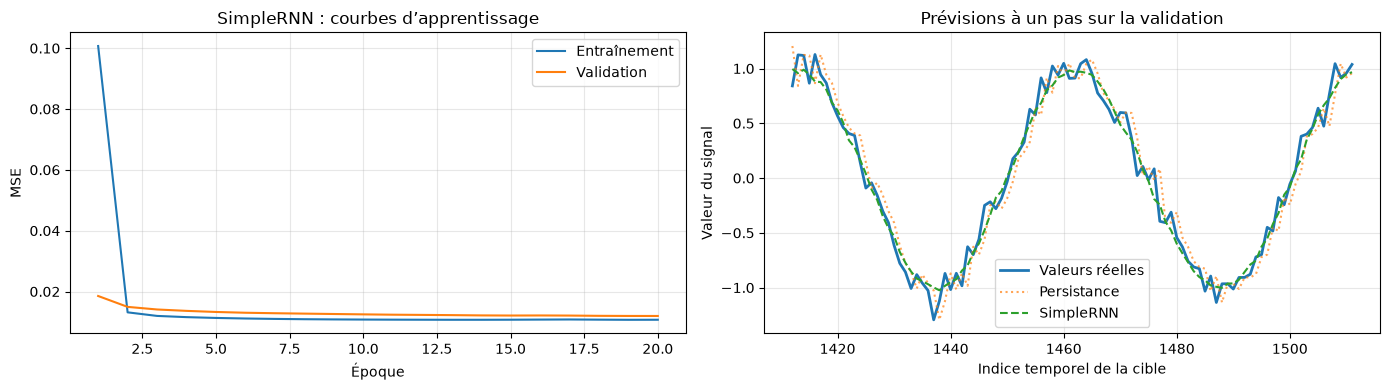

Figure enregistrée : figures/05_SimpleRNN_validation.png
Métriques et prévisions enregistrées dans resultats/.


In [19]:
# Prédire sans entraîner : les poids restent fixes.
predictions_rnn_val = modele_rnn.predict(
    X_val, batch_size=TAILLE_LOT, verbose=0)
metriques_rnn_val = calculer_metriques(y_val, predictions_rnn_val)

comparaison_rnn_val = pd.concat([
    reference_validation,
    pd.DataFrame([{
        'Modèle': 'SimpleRNN',
        'Jeu': 'Validation',
        'MAE': metriques_rnn_val['MAE'],
        'RMSE': metriques_rnn_val['RMSE'],
        'Paramètres entraînables': modele_rnn.count_params(),
    }]),
], ignore_index=True)
print(comparaison_rnn_val.to_string(
    index=False, float_format=lambda valeur: f'{valeur:.4f}'))
reduction_mae_rnn = 100 * (
    1 - metriques_rnn_val['MAE'] / metriques_naives_val['MAE'])
print(f'\nRéduction relative de MAE face à la persistance : {reduction_mae_rnn:.1f} %')
comparaison_rnn_val.to_csv(
    DOSSIER_RESULTATS / 'comparaison_SimpleRNN_validation.csv', index=False)

# Conserver les prévisions exactes pour les comparaisons ultérieures.
pd.DataFrame({
    'indice_cible': t_val,
    'valeur_reelle': y_val[:, 0],
    'persistance': predictions_naives_val,
    'SimpleRNN': predictions_rnn_val[:, 0],
}).to_csv(DOSSIER_RESULTATS / 'predictions_SimpleRNN_validation.csv', index=False)

# Représenter l'apprentissage et les prévisions dans une même figure.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(tableau_historique_rnn['epoque'], tableau_historique_rnn['loss'],
             label='Entraînement')
axes[0].plot(tableau_historique_rnn['epoque'], tableau_historique_rnn['val_loss'],
             label='Validation')
axes[0].set_title('SimpleRNN : courbes d’apprentissage')
axes[0].set_xlabel('Époque')
axes[0].set_ylabel('MSE')
axes[0].legend()
axes[0].grid(alpha=0.3)

n_affiches = min(100, len(y_val))
axes[1].plot(t_val[:n_affiches], y_val[:n_affiches, 0],
             label='Valeurs réelles', linewidth=2)
axes[1].plot(t_val[:n_affiches], predictions_naives_val[:n_affiches],
             label='Persistance', linestyle=':', alpha=0.7)
axes[1].plot(t_val[:n_affiches], predictions_rnn_val[:n_affiches, 0],
             label='SimpleRNN', linestyle='--')
axes[1].set_title('Prévisions à un pas sur la validation')
axes[1].set_xlabel('Indice temporel de la cible')
axes[1].set_ylabel('Valeur du signal')
axes[1].legend()
axes[1].grid(alpha=0.3)
fig.tight_layout()
chemin_figure = DOSSIER_FIGURES / '05_SimpleRNN_validation.png'
fig.savefig(chemin_figure, dpi=200, bbox_inches='tight')
plt.show()
print('Figure enregistrée :', chemin_figure)
print('Métriques et prévisions enregistrées dans resultats/.')

## 10. Entraîner LSTM avec le même protocole

Nous gardons les mêmes données, 32 unités, Adam à 0,001, des lots de 32 et 20 époques fixes, sans mélange des fenêtres et sans arrêt anticipé. Le modèle final sera évalué après les 20 époques, comme SimpleRNN. Le test reste inutilisé.

LSTM possède un état caché et un état de cellule. Ses portes apprennent à réguler les informations conservées, ajoutées et transmises. Avec 32 unités, ces deux états ont chacun 32 composantes ; l'état de cellule n'ajoute pas un deuxième axe aux données d'entrée. La forme d'entrée reste `(40, 1)`.

Ses 4 385 paramètres ne garantissent pas une meilleure prévision que les 1 121 paramètres de SimpleRNN sur ce signal simple. Nous observerons les résultats.

La classe de suivi définie dans la cellule de SimpleRNN est réutilisée. Chaque modèle est reconstruit avant son entraînement. Une nouvelle exécution recommence depuis zéro et remplace les fichiers LSTM. La durée totale inclut les coûts de démarrage éventuels ; les durées par époque seront également conservées.

In [20]:
# Construire une LSTM neuve avec les mêmes réglages et la même graine.
modele_lstm = construire_modele('LSTM')
suivi_lstm = SuiviEntrainement()
print('Début de l’entraînement de LSTM.', flush=True)
print('La première époque peut inclure une initialisation GPU supplémentaire.', flush=True)

debut_lstm = time.perf_counter()
historique_lstm = modele_lstm.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=N_EPOQUES,
    batch_size=TAILLE_LOT,
    shuffle=False,
    callbacks=[suivi_lstm],
    verbose=0,
)
duree_lstm = time.perf_counter() - debut_lstm
modeles['LSTM'] = modele_lstm

# Sauvegarder le modèle final et les mesures, sans toucher à SimpleRNN.
modele_lstm.save(DOSSIER_MODELES / 'LSTM.keras')
tableau_historique_lstm = pd.DataFrame(historique_lstm.history)
tableau_historique_lstm.insert(0, 'epoque', np.arange(1, N_EPOQUES + 1))
tableau_historique_lstm['duree_secondes'] = suivi_lstm.durees_epoques
tableau_historique_lstm.to_csv(
    DOSSIER_RESULTATS / 'historique_LSTM.csv', index=False)

pd.DataFrame([{
    'Modèle': 'LSTM',
    'Époques': N_EPOQUES,
    'Taille de lot': TAILLE_LOT,
    'Durée totale fit (s)': duree_lstm,
    'Durée première époque (s)': suivi_lstm.durees_epoques[0],
    'Durée médiane époques 2 à 20 (s)': float(np.median(suivi_lstm.durees_epoques[1:])),
}]).to_csv(DOSSIER_RESULTATS / 'temps_LSTM.csv', index=False)

print(f'\nEntraînement terminé en {duree_lstm:.2f} secondes.')
print('Modèle enregistré : modeles/LSTM.keras')
print('Historique et durées enregistrés dans resultats/.')

Début de l’entraînement de LSTM.
La première époque peut inclure une initialisation GPU supplémentaire.
Époque 01/20 | MSE entraînement : 0.23273 | MSE validation : 0.04621 | Durée : 5.65 s
Époque 02/20 | MSE entraînement : 0.01598 | MSE validation : 0.01212 | Durée : 0.41 s
Époque 03/20 | MSE entraînement : 0.01146 | MSE validation : 0.01191 | Durée : 0.42 s
Époque 04/20 | MSE entraînement : 0.01129 | MSE validation : 0.01187 | Durée : 0.41 s
Époque 05/20 | MSE entraînement : 0.01120 | MSE validation : 0.01186 | Durée : 0.41 s
Époque 06/20 | MSE entraînement : 0.01114 | MSE validation : 0.01187 | Durée : 0.41 s
Époque 07/20 | MSE entraînement : 0.01111 | MSE validation : 0.01189 | Durée : 0.42 s
Époque 08/20 | MSE entraînement : 0.01109 | MSE validation : 0.01190 | Durée : 0.41 s
Époque 09/20 | MSE entraînement : 0.01107 | MSE validation : 0.01190 | Durée : 0.41 s
Époque 10/20 | MSE entraînement : 0.01106 | MSE validation : 0.01189 | Durée : 0.41 s
Époque 11/20 | MSE entraînement : 0.

## 11. Évaluer LSTM sur la validation

Le modèle final de LSTM est évalué sur les mêmes 294 exemples que SimpleRNN et la persistance, avec la même fonction MAE/RMSE. La comparaison affichera les trois résultats. Le test reste réservé à la fin.

Une différence faible sur une seule exécution ne suffit pas à établir une supériorité générale : l'initialisation et le jeu de données influencent les résultats. Nous conservons les réglages prévus plutôt que de les modifier pour favoriser une architecture.

Les graphiques montrent la MSE au fil des époques et les prévisions de LSTM face aux mesures et à la persistance. Le modèle n'est pas entraîné dans cette cellule.

                       Modèle        Jeu    MAE   RMSE  Paramètres entraînables
Persistance (référence naïve) Validation 0.1425 0.1765                        0
                    SimpleRNN Validation 0.0866 0.1094                     1121
                         LSTM Validation 0.0865 0.1088                     4385

Réduction relative de MAE face à la persistance : 39.3 %


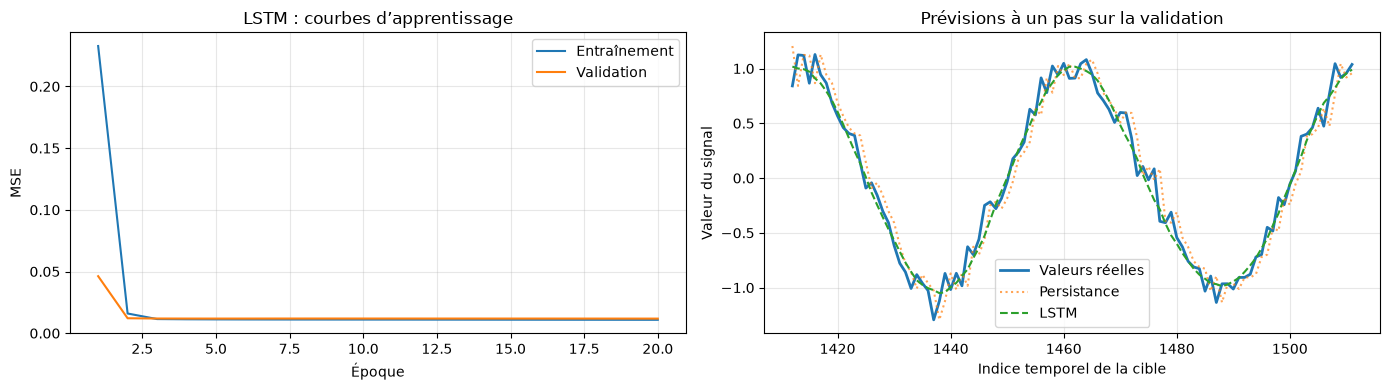

Figure enregistrée : figures/06_LSTM_validation.png
Métriques et prévisions enregistrées dans resultats/.


In [22]:
# Prédire sans entraîner : les poids restent fixes.
predictions_lstm_val = modele_lstm.predict(
    X_val, batch_size=TAILLE_LOT, verbose=0)
metriques_lstm_val = calculer_metriques(y_val, predictions_lstm_val)

comparaison_lstm_val = pd.concat([
    comparaison_rnn_val,
    pd.DataFrame([{
        'Modèle': 'LSTM',
        'Jeu': 'Validation',
        'MAE': metriques_lstm_val['MAE'],
        'RMSE': metriques_lstm_val['RMSE'],
        'Paramètres entraînables': modele_lstm.count_params(),
    }]),
], ignore_index=True)
print(comparaison_lstm_val.to_string(
    index=False, float_format=lambda valeur: f'{valeur:.4f}'))
reduction_mae_lstm = 100 * (
    1 - metriques_lstm_val['MAE'] / metriques_naives_val['MAE'])
print(f'\nRéduction relative de MAE face à la persistance : {reduction_mae_lstm:.1f} %')
comparaison_lstm_val.to_csv(
    DOSSIER_RESULTATS / 'comparaison_LSTM_validation.csv', index=False)

# Conserver les prévisions exactes pour les comparaisons ultérieures.
pd.DataFrame({
    'indice_cible': t_val,
    'valeur_reelle': y_val[:, 0],
    'persistance': predictions_naives_val,
    'LSTM': predictions_lstm_val[:, 0],
}).to_csv(DOSSIER_RESULTATS / 'predictions_LSTM_validation.csv', index=False)

# Représenter l'apprentissage et les prévisions dans une même figure.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(tableau_historique_lstm['epoque'], tableau_historique_lstm['loss'],
             label='Entraînement')
axes[0].plot(tableau_historique_lstm['epoque'], tableau_historique_lstm['val_loss'],
             label='Validation')
axes[0].set_title('LSTM : courbes d’apprentissage')
axes[0].set_xlabel('Époque')
axes[0].set_ylabel('MSE')
axes[0].legend()
axes[0].grid(alpha=0.3)

n_affiches = min(100, len(y_val))
axes[1].plot(t_val[:n_affiches], y_val[:n_affiches, 0],
             label='Valeurs réelles', linewidth=2)
axes[1].plot(t_val[:n_affiches], predictions_naives_val[:n_affiches],
             label='Persistance', linestyle=':', alpha=0.7)
axes[1].plot(t_val[:n_affiches], predictions_lstm_val[:n_affiches, 0],
             label='LSTM', linestyle='--')
axes[1].set_title('Prévisions à un pas sur la validation')
axes[1].set_xlabel('Indice temporel de la cible')
axes[1].set_ylabel('Valeur du signal')
axes[1].legend()
axes[1].grid(alpha=0.3)
fig.tight_layout()
chemin_figure = DOSSIER_FIGURES / '06_LSTM_validation.png'
fig.savefig(chemin_figure, dpi=200, bbox_inches='tight')
plt.show()
print('Figure enregistrée :', chemin_figure)
print('Métriques et prévisions enregistrées dans resultats/.')

## 12. Entraîner GRU avec le même protocole

La GRU utilise une porte de mise à jour et une porte de réinitialisation pour réguler l'utilisation du passé. Contrairement à LSTM, elle n'a pas d'état de cellule séparé : son état caché comporte ici 32 composantes.

Nous conservons les mêmes fenêtres et divisions, 32 unités récurrentes, Adam à 0,001, des lots de 32, 20 époques fixes et `shuffle=False`. Le modèle final est sauvegardé après les 20 époques. Aucun réglage n'est modifié à partir des résultats précédents. Le test reste inutilisé.

Avec 3 393 paramètres, GRU se situe entre SimpleRNN et LSTM en nombre de paramètres. Cela ne garantit pas un classement identique pour la précision ou la vitesse. Nous mesurerons son comportement.

Cette cellule réutilise la classe de suivi définie au chapitre 8. Une nouvelle exécution reconstruit GRU depuis zéro et remplace ses fichiers. Le chronométrage inclut les coûts de démarrage éventuels, enregistrés aussi séparément via la première époque.

In [23]:
# Construire une GRU neuve avec les mêmes réglages et la même graine.
modele_gru = construire_modele('GRU')
suivi_gru = SuiviEntrainement()
print('Début de l’entraînement de GRU.', flush=True)
print('La première époque peut inclure une initialisation GPU supplémentaire.', flush=True)

debut_gru = time.perf_counter()
historique_gru = modele_gru.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=N_EPOQUES,
    batch_size=TAILLE_LOT,
    shuffle=False,
    callbacks=[suivi_gru],
    verbose=0,
)
duree_gru = time.perf_counter() - debut_gru
modeles['GRU'] = modele_gru

# Sauvegarder le modèle final et les mesures, sans toucher à SimpleRNN.
modele_gru.save(DOSSIER_MODELES / 'GRU.keras')
tableau_historique_gru = pd.DataFrame(historique_gru.history)
tableau_historique_gru.insert(0, 'epoque', np.arange(1, N_EPOQUES + 1))
tableau_historique_gru['duree_secondes'] = suivi_gru.durees_epoques
tableau_historique_gru.to_csv(
    DOSSIER_RESULTATS / 'historique_GRU.csv', index=False)

pd.DataFrame([{
    'Modèle': 'GRU',
    'Époques': N_EPOQUES,
    'Taille de lot': TAILLE_LOT,
    'Durée totale fit (s)': duree_gru,
    'Durée première époque (s)': suivi_gru.durees_epoques[0],
    'Durée médiane époques 2 à 20 (s)': float(np.median(suivi_gru.durees_epoques[1:])),
}]).to_csv(DOSSIER_RESULTATS / 'temps_GRU.csv', index=False)

print(f'\nEntraînement terminé en {duree_gru:.2f} secondes.')
print('Modèle enregistré : modeles/GRU.keras')
print('Historique et durées enregistrés dans resultats/.')

Début de l’entraînement de GRU.
La première époque peut inclure une initialisation GPU supplémentaire.
Époque 01/20 | MSE entraînement : 0.19231 | MSE validation : 0.07407 | Durée : 1.15 s
Époque 02/20 | MSE entraînement : 0.05439 | MSE validation : 0.04146 | Durée : 0.45 s
Époque 03/20 | MSE entraînement : 0.02824 | MSE validation : 0.01890 | Durée : 0.43 s
Époque 04/20 | MSE entraînement : 0.01482 | MSE validation : 0.01524 | Durée : 0.45 s
Époque 05/20 | MSE entraînement : 0.01407 | MSE validation : 0.01506 | Durée : 0.46 s
Époque 06/20 | MSE entraînement : 0.01385 | MSE validation : 0.01487 | Durée : 0.43 s
Époque 07/20 | MSE entraînement : 0.01364 | MSE validation : 0.01469 | Durée : 0.43 s
Époque 08/20 | MSE entraînement : 0.01344 | MSE validation : 0.01451 | Durée : 0.42 s
Époque 09/20 | MSE entraînement : 0.01324 | MSE validation : 0.01433 | Durée : 0.40 s
Époque 10/20 | MSE entraînement : 0.01305 | MSE validation : 0.01415 | Durée : 0.40 s
Époque 11/20 | MSE entraînement : 0.0

## 13. Évaluer GRU et compléter la comparaison sur la validation

Nous utilisons GRU après les 20 époques prévues et calculons les mêmes MAE/RMSE sur les mêmes 294 cibles de validation. Le tableau rassemble la persistance et les trois réseaux. Aucun entraînement et aucune évaluation du test ne sont effectués ici.

La MSE de validation de GRU diminue encore à l'époque 20. Un score moins bon dans ce protocole ne signifie donc pas que GRU serait toujours moins performante : il décrit ce budget d'entraînement, cette initialisation et ces données. Nous gardons les 20 époques communes et ne changeons pas le protocole après avoir vu les résultats.

Le temps total plus court observé pour GRU inclut un démarrage différent. Il ne suffit pas à conclure que ses époques sont plus rapides : les durées médianes après la première époque seront également comparées.

La figure et les fichiers CSV alimenteront la présentation. La comparaison finale sur le test viendra ensuite, avec les modèles et réglages déjà fixés.

                       Modèle        Jeu    MAE   RMSE  Paramètres entraînables
Persistance (référence naïve) Validation 0.1425 0.1765                        0
                    SimpleRNN Validation 0.0866 0.1094                     1121
                         LSTM Validation 0.0865 0.1088                     4385
                          GRU Validation 0.0899 0.1130                     3393

Réduction relative de MAE face à la persistance : 36.9 %


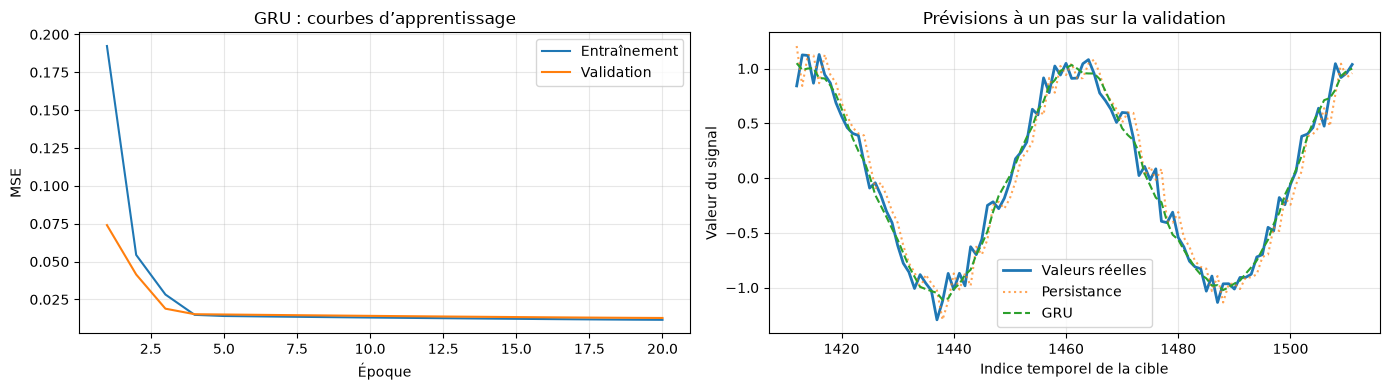

Figure enregistrée : figures/07_GRU_validation.png
Métriques et prévisions enregistrées dans resultats/.


In [26]:
# Prédire sans entraîner : les poids restent fixes.
predictions_gru_val = modele_gru.predict(
    X_val, batch_size=TAILLE_LOT, verbose=0)
metriques_gru_val = calculer_metriques(y_val, predictions_gru_val)

comparaison_gru_val = pd.concat([
    comparaison_lstm_val,
    pd.DataFrame([{
        'Modèle': 'GRU',
        'Jeu': 'Validation',
        'MAE': metriques_gru_val['MAE'],
        'RMSE': metriques_gru_val['RMSE'],
        'Paramètres entraînables': modele_gru.count_params(),
    }]),
], ignore_index=True)
print(comparaison_gru_val.to_string(
    index=False, float_format=lambda valeur: f'{valeur:.4f}'))
reduction_mae_gru = 100 * (
    1 - metriques_gru_val['MAE'] / metriques_naives_val['MAE'])
print(f'\nRéduction relative de MAE face à la persistance : {reduction_mae_gru:.1f} %')
comparaison_gru_val.to_csv(
    DOSSIER_RESULTATS / 'comparaison_GRU_validation.csv', index=False)

# Conserver les prévisions exactes pour les comparaisons ultérieures.
pd.DataFrame({
    'indice_cible': t_val,
    'valeur_reelle': y_val[:, 0],
    'persistance': predictions_naives_val,
    'GRU': predictions_gru_val[:, 0],
}).to_csv(DOSSIER_RESULTATS / 'predictions_GRU_validation.csv', index=False)

# Représenter l'apprentissage et les prévisions dans une même figure.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(tableau_historique_gru['epoque'], tableau_historique_gru['loss'],
             label='Entraînement')
axes[0].plot(tableau_historique_gru['epoque'], tableau_historique_gru['val_loss'],
             label='Validation')
axes[0].set_title('GRU : courbes d’apprentissage')
axes[0].set_xlabel('Époque')
axes[0].set_ylabel('MSE')
axes[0].legend()
axes[0].grid(alpha=0.3)

n_affiches = min(100, len(y_val))
axes[1].plot(t_val[:n_affiches], y_val[:n_affiches, 0],
             label='Valeurs réelles', linewidth=2)
axes[1].plot(t_val[:n_affiches], predictions_naives_val[:n_affiches],
             label='Persistance', linestyle=':', alpha=0.7)
axes[1].plot(t_val[:n_affiches], predictions_gru_val[:n_affiches, 0],
             label='GRU', linestyle='--')
axes[1].set_title('Prévisions à un pas sur la validation')
axes[1].set_xlabel('Indice temporel de la cible')
axes[1].set_ylabel('Valeur du signal')
axes[1].legend()
axes[1].grid(alpha=0.3)
fig.tight_layout()
chemin_figure = DOSSIER_FIGURES / '07_GRU_validation.png'
fig.savefig(chemin_figure, dpi=200, bbox_inches='tight')
plt.show()
print('Figure enregistrée :', chemin_figure)
print('Métriques et prévisions enregistrées dans resultats/.')

## 14. Évaluation finale sur le test réservé

Les trois modèles sont fixés : 32 unités, Adam à 0,001, 20 époques et lots de 32. Nous évaluons leurs poids finaux, sans réentraînement et sans choix supplémentaire à partir du test.

Les 294 cibles du test vont de l'indice 1706 à 1999. Chaque prévision utilise les 40 observations réelles précédentes : évaluation glissante à un pas. Ce protocole ne correspond pas à prévoir 294 valeurs d'un seul coup sans recevoir de nouvelles observations.

Nous calculons MAE et RMSE pour la persistance et chaque réseau, puis rassemblons les paramètres et les temps de fit déjà enregistrés. La persistance n'a pas d'entraînement : sa durée d'entraînement est indiquée comme non applicable, pas comme une durée mesurée nulle.

Les temps incluent des coûts de démarrage différents. La médiane des époques 2 à 20 complète le temps total, sans constituer un benchmark répété. Les résultats décrivent une exécution par architecture sur un signal synthétique simple ; ils ne prouvent pas une supériorité générale.

Les tableaux et les figures sont sauvegardés pour la présentation. Après lecture du test, nous ne modifierons pas les modèles pour améliorer leurs scores sur ce même test.

     Modèle  Jeu    MAE   RMSE  Réduction MAE / persistance (%)  Paramètres entraînables  Durée totale fit (s)  Durée première époque (s)  Durée médiane époques 2 à 20 (s)
Persistance Test 0.1361 0.1683                           0.0000                        0        Non applicable             Non applicable                    Non applicable
  SimpleRNN Test 0.0819 0.1035                          39.8263                     1121               12.2114                     4.1828                            0.4192
       LSTM Test 0.0809 0.1021                          40.5511                     4385               13.7304                     5.6492                            0.4157
        GRU Test 0.0850 0.1067                          37.5679                     3393                9.3787                     1.1464                            0.4314


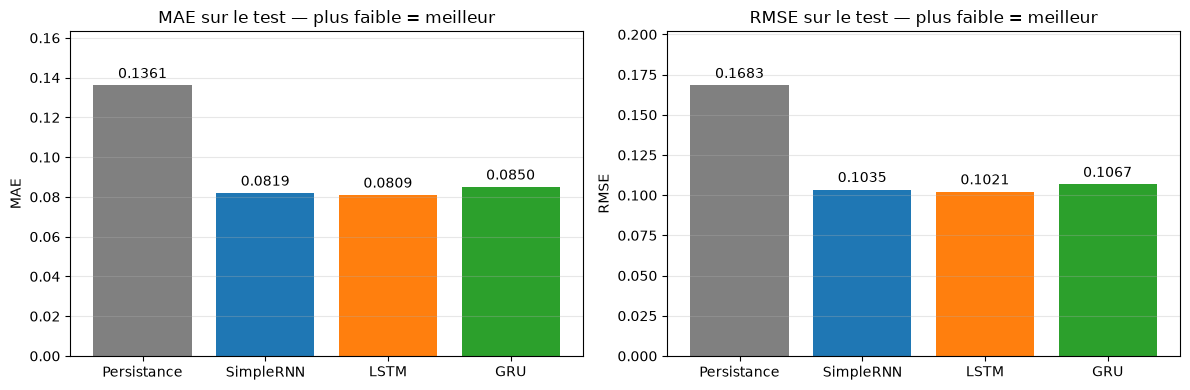

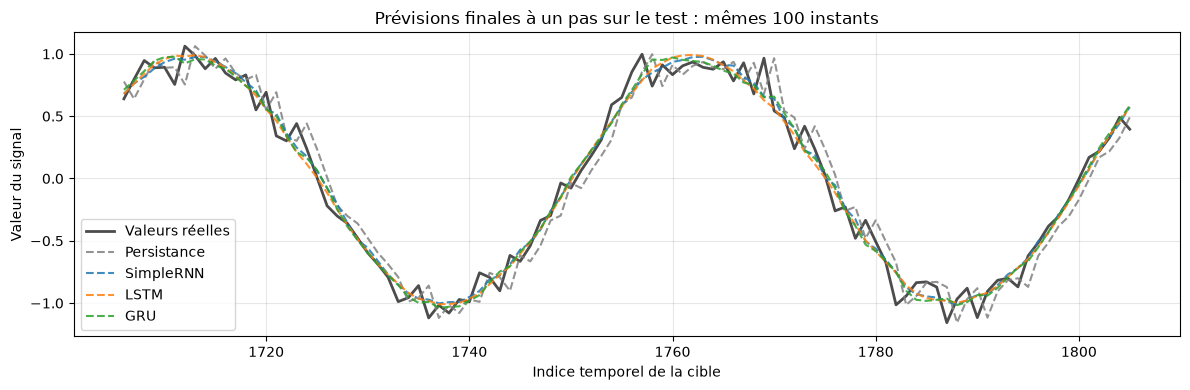

Comparaison et prévisions finales enregistrées dans resultats/.
Figures enregistrées : 08_erreurs_test.png et 09_predictions_test.png


In [28]:
# Obtenir les prévisions finales, sans modifier les poids.
predictions_test = {'Persistance': X_test[:, -1, 0]}
for nom in ['SimpleRNN', 'LSTM', 'GRU']:
    predictions_test[nom] = modeles[nom].predict(
        X_test, batch_size=TAILLE_LOT, verbose=0).reshape(-1)

metriques_reference_test = calculer_metriques(y_test, predictions_test['Persistance'])
lignes_test = []
for nom, predictions in predictions_test.items():
    mesures = calculer_metriques(y_test, predictions)
    ligne = {
        'Modèle': nom,
        'Jeu': 'Test',
        'MAE': mesures['MAE'],
        'RMSE': mesures['RMSE'],
        'Réduction MAE / persistance (%)': 100 * (
            1 - mesures['MAE'] / metriques_reference_test['MAE']),
        'Paramètres entraînables': 0 if nom == 'Persistance' else modeles[nom].count_params(),
        'Durée totale fit (s)': np.nan,
        'Durée première époque (s)': np.nan,
        'Durée médiane époques 2 à 20 (s)': np.nan,
    }
    if nom != 'Persistance':
        temps_modele = pd.read_csv(DOSSIER_RESULTATS / f'temps_{nom}.csv').iloc[0]
        for colonne in ['Durée totale fit (s)', 'Durée première époque (s)',
                        'Durée médiane époques 2 à 20 (s)']:
            ligne[colonne] = float(temps_modele[colonne])
    lignes_test.append(ligne)

comparaison_test = pd.DataFrame(lignes_test)
print(comparaison_test.to_string(
    index=False, na_rep='Non applicable',
    float_format=lambda valeur: f'{valeur:.4f}'))
comparaison_test.to_csv(DOSSIER_RESULTATS / 'comparaison_finale_test.csv', index=False)

# Conserver toutes les prévisions du test pour les analyses et les figures.
tableau_predictions_test = pd.DataFrame({
    'indice_cible': t_test,
    'valeur_reelle': y_test[:, 0],
    **predictions_test,
})
tableau_predictions_test.to_csv(
    DOSSIER_RESULTATS / 'predictions_finales_test.csv', index=False)

# Graphique des deux mesures d'erreur, calculées sur le même test.
couleurs = ['gray', 'tab:blue', 'tab:orange', 'tab:green']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, mesure in zip(axes, ['MAE', 'RMSE']):
    barres = ax.bar(comparaison_test['Modèle'], comparaison_test[mesure], color=couleurs)
    ax.bar_label(barres, fmt='%.4f', padding=3)
    ax.set_ylim(0, comparaison_test[mesure].max() * 1.2)
    ax.set_title(f'{mesure} sur le test — plus faible = meilleur')
    ax.set_ylabel(mesure)
    ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / '08_erreurs_test.png', dpi=200, bbox_inches='tight')
plt.show()

# Comparer visuellement les prévisions sur les 100 premiers instants du test.
fig, ax = plt.subplots(figsize=(12, 4))
n_affiches = min(100, len(y_test))
ax.plot(t_test[:n_affiches], y_test[:n_affiches, 0],
        label='Valeurs réelles', color='black', linewidth=2, alpha=0.7)
for (nom, predictions), couleur in zip(predictions_test.items(), couleurs):
    ax.plot(t_test[:n_affiches], predictions[:n_affiches],
            label=nom, color=couleur, linestyle='--', alpha=0.85)
ax.set_title('Prévisions finales à un pas sur le test : mêmes 100 instants')
ax.set_xlabel('Indice temporel de la cible')
ax.set_ylabel('Valeur du signal')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / '09_predictions_test.png', dpi=200, bbox_inches='tight')
plt.show()
print('Comparaison et prévisions finales enregistrées dans resultats/.')
print('Figures enregistrées : 08_erreurs_test.png et 09_predictions_test.png')

## 15. Préparer les figures comparatives pour la présentation

Cette cellule lit uniquement les fichiers CSV déjà enregistrés. Elle ne réentraîne aucun modèle et ne recalcule aucun score de test.

La première figure compare les courbes de MSE des trois réseaux. Une échelle logarithmique rend visibles les écarts entre petites pertes sans masquer les premières époques plus élevées. Les graduations doivent donc être lues avec attention.

La deuxième figure compare le nombre de paramètres, le temps total de fit et la durée médiane des époques 2 à 20. Chaque grandeur a son propre graphique et sa propre unité. Les temps dépendent du matériel, du démarrage, des implémentations et de l'ordre d'exécution. Une seule mesure par modèle ne permet pas d'établir un classement universel de vitesse.

Ces graphiques complètent les erreurs et prévisions du test pour discuter le compromis entre précision, taille et coût mesuré. Nous n'ajustons plus les modèles après lecture des résultats du test.

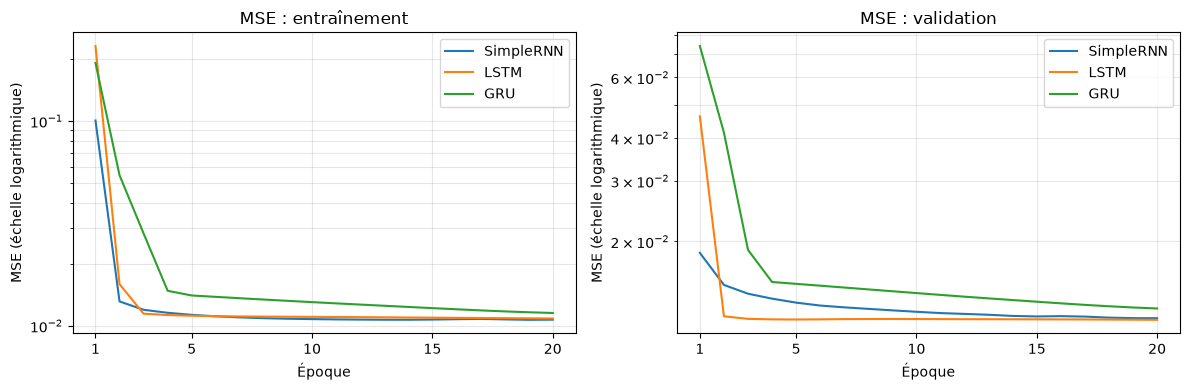

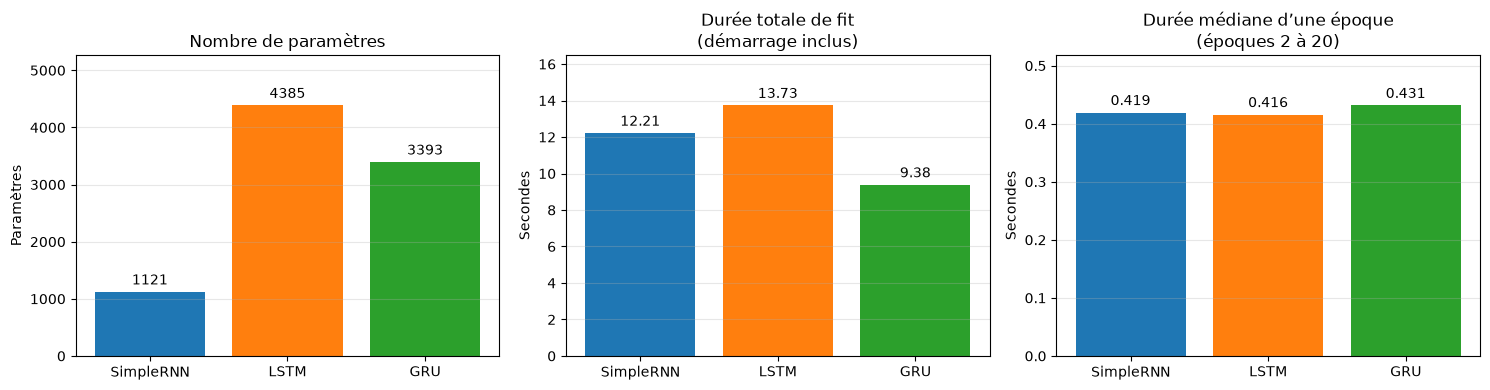

Figures enregistrées : 10_courbes_comparatives.png et 11_parametres_et_durees.png
Ces figures décrivent une seule exécution par architecture sur cette machine.


In [29]:
# Relire les résultats sauvegardés : aucun entraînement supplémentaire.
noms_modeles = ['SimpleRNN', 'LSTM', 'GRU']
couleurs_modeles = ['tab:blue', 'tab:orange', 'tab:green']
historiques_sauvegardes = {
    nom: pd.read_csv(DOSSIER_RESULTATS / f'historique_{nom}.csv')
    for nom in noms_modeles
}
bilan_test = pd.read_csv(DOSSIER_RESULTATS / 'comparaison_finale_test.csv')
bilan_reseaux = bilan_test.set_index('Modèle').loc[noms_modeles]

# Comparer les courbes avec la même échelle pour les trois architectures.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for nom, couleur in zip(noms_modeles, couleurs_modeles):
    historique = historiques_sauvegardes[nom]
    axes[0].plot(historique['epoque'], historique['loss'], label=nom, color=couleur)
    axes[1].plot(historique['epoque'], historique['val_loss'], label=nom, color=couleur)
for ax, titre in zip(axes, ['Entraînement', 'Validation']):
    ax.set_title(f'MSE : {titre.lower()}')
    ax.set_xlabel('Époque')
    ax.set_ylabel('MSE (échelle logarithmique)')
    ax.set_yscale('log')
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.legend()
    ax.grid(alpha=0.3, which='both')
fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / '10_courbes_comparatives.png', dpi=200, bbox_inches='tight')
plt.show()

# Distinguer explicitement taille, temps global et temps après démarrage.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colonnes = [
    ('Paramètres entraînables', 'Nombre de paramètres', 'Paramètres', '%.0f'),
    ('Durée totale fit (s)', 'Durée totale de fit\n(démarrage inclus)', 'Secondes', '%.2f'),
    ('Durée médiane époques 2 à 20 (s)', 'Durée médiane d’une époque\n(époques 2 à 20)', 'Secondes', '%.3f'),
]
for ax, (colonne, titre, unite, format_nombre) in zip(axes, colonnes):
    valeurs = bilan_reseaux[colonne]
    barres = ax.bar(noms_modeles, valeurs, color=couleurs_modeles)
    ax.bar_label(barres, fmt=format_nombre, padding=3)
    ax.set_ylim(0, valeurs.max() * 1.2)
    ax.set_title(titre)
    ax.set_ylabel(unite)
    ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / '11_parametres_et_durees.png', dpi=200, bbox_inches='tight')
plt.show()
print('Figures enregistrées : 10_courbes_comparatives.png et 11_parametres_et_durees.png')
print('Ces figures décrivent une seule exécution par architecture sur cette machine.')